In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report, roc_auc_score,roc_curve

In [2]:
credit=pd.read_csv(r"C:\Users\Lenovo\Downloads\Python for Data Science  NOI  APR 2026   Class 21 Python for Data Science  NOI  APR 2026\credit_data - 1782056531013.csv")

In [3]:
credit.head()

,age,annual_income,credit_score,loan_amount,dti,missed_payments,employment_type,default
0,26,82684,785,12076,18.6,1,Salaried,0
1,33,71887,663,13016,13.2,0,Salaried,0
2,46,60646,651,20958,10.3,1,Self_Employed,0
3,53,47142,521,22870,24.8,1,Salaried,1
4,35,65893,680,30378,5.5,2,Self_Employed,0


In [4]:
credit.shape

(400, 8)

In [5]:
credit.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              400 non-null    int64  
 1   annual_income    400 non-null    int64  
 2   credit_score     400 non-null    int64  
 3   loan_amount      400 non-null    int64  
 4   dti              400 non-null    float64
 5   missed_payments  400 non-null    int64  
 6   employment_type  400 non-null    str    
 7   default          400 non-null    int64  
dtypes: float64(1), int64(6), str(1)
memory usage: 28.9 KB


In [6]:
credit["default"].value_counts()

default
0    252
1    148
Name: count, dtype: int64

In [7]:
credit_ready=pd.get_dummies(credit,columns=["employment_type"],drop_first=True)


for column in credit_ready.columns:
    if credit_ready[column].dtype==bool:
        credit_ready[column]=credit_ready[column].astype(int)
1
credit_ready.head()

,age,annual_income,credit_score,loan_amount,dti,missed_payments,default,employment_type_Self_Employed
0,26,82684,785,12076,18.6,1,0,0
1,33,71887,663,13016,13.2,0,0,0
2,46,60646,651,20958,10.3,1,0,1
3,53,47142,521,22870,24.8,1,1,0
4,35,65893,680,30378,5.5,2,0,1


In [8]:
y=credit_ready["default"]
x=credit_ready.drop(columns=["default"])
print("features",list(x.columns))

features ['age', 'annual_income', 'credit_score', 'loan_amount', 'dti', 'missed_payments', 'employment_type_Self_Employed']


In [9]:
y

0      0
1      0
2      0
3      1
4      0
      ..
395    0
396    0
397    1
398    0
399    1
Name: default, Length: 400, dtype: int64

In [10]:
X_train,X_test,Y_train,Y_test=train_test_split(x,y,test_size=0.2,random_state=1)
print('training rows',X_train.shape[0])
print('testing rows',X_test.shape[0])

training rows 320
testing rows 80


In [11]:
x_train=sm.add_constant(X_train)

In [12]:
x_train.head()

,const,age,annual_income,credit_score,loan_amount,dti,missed_payments,employment_type_Self_Employed
93,1.0,41,68106,622,12423,12.3,1,1
23,1.0,44,72093,773,20781,23.9,1,1
299,1.0,34,67541,622,25646,20.2,1,0
13,1.0,39,55618,714,26251,34.4,1,0
90,1.0,21,69339,649,13699,14.9,1,1


In [13]:
model=sm.Logit(Y_train,x_train).fit()

Optimization terminated successfully.
         Current function value: 0.461038
         Iterations 7


In [14]:
print(model.summary())

                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                  320
Model:                          Logit   Df Residuals:                      312
Method:                           MLE   Df Model:                            7
Date:                Sat, 03 Oct 2026   Pseudo R-squ.:                  0.2960
Time:                        00:31:52   Log-Likelihood:                -147.53
converged:                       True   LL-Null:                       -209.55
Covariance Type:            nonrobust   LLR p-value:                 1.105e-23
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                            12.1302      2.195      5.526      0.000       7.828      16.432
age                               0.0129      0.015      0.883      0.377 

In [15]:
for name in model.pvalues.index:
    if name == "const":
        continue
    p = model.pvalues[name]
    if p < 0.05:
        print(name, "-> p =", round(p, 4), "-> significant (a real driver)")
    else:
        print(name, "-> p =", round(p, 4), "-> not significant")

age -> p = 0.3775 -> not significant
annual_income -> p = 0.0531 -> not significant
credit_score -> p = 0.0 -> significant (a real driver)
loan_amount -> p = 0.4481 -> not significant
dti -> p = 0.0 -> significant (a real driver)
missed_payments -> p = 0.0 -> significant (a real driver)
employment_type_Self_Employed -> p = 0.2814 -> not significant


In [16]:
weak_features =["annual_income","loan_amount","employment_type_Self_Employed"]

X_small=x_train.drop(columns=weak_features)

Xt_small=X_test.drop(columns=weak_features)


In [17]:
x_small=sm.add_constant(X_small)
xt_small=sm.add_constant(Xt_small)

In [18]:
models=sm.Logit(Y_train,x_small).fit()

Optimization terminated successfully.
         Current function value: 0.469667
         Iterations 7


In [19]:
pred_prob=models.predict(xt_small)

pred_class=(pred_prob>=0.5).astype(int)

preview=pd.DataFrame()
preview["probability"]=pred_prob.round(3).values
preview["predicted"]=pred_class.values
preview["actual"]=Y_test.values
preview.head(8)

,probability,predicted,actual
0,0.231,0,0
1,0.238,0,1
2,0.124,0,0
3,0.017,0,0
4,0.474,0,0
5,0.749,1,1
6,0.049,0,0
7,0.035,0,0


In [20]:
#confusion matrix
cm=confusion_matrix(Y_test,pred_class)
cm_table=pd.DataFrame(cm,
                     index=["actual No(0)","actual Yes(1)"],
                     columns=['predicted no(0)','predicted yes(1)'])
cm_table


,predicted no(0),predicted yes(1)
actual No(0),42,6
actual Yes(1),16,16


In [21]:
wrong=(pred_class!=Y_test).sum()
total=len(Y_test)
print("wrong predictions",wrong ,"out of", total)

wrong predictions 22 out of 80


In [22]:
print(classification_report(Y_test,pred_class,target_names=["No Default","Default"]))

              precision    recall  f1-score   support

  No Default       0.72      0.88      0.79        48
     Default       0.73      0.50      0.59        32

    accuracy                           0.72        80
   macro avg       0.73      0.69      0.69        80
weighted avg       0.73      0.72      0.71        80



ROC_AUC: 0.858
-> strong separation between defaulters and non-defaulters


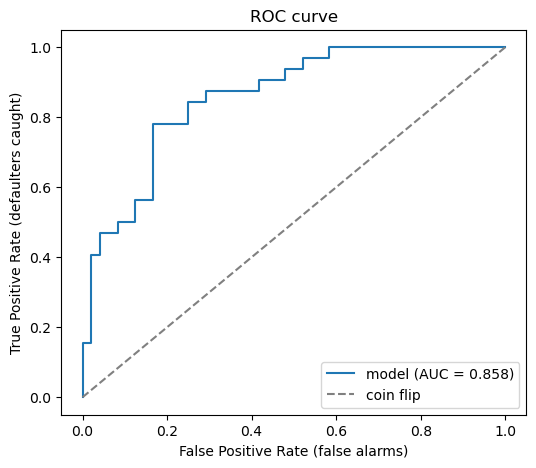

In [23]:
auc= roc_auc_score(Y_test,pred_prob)
print('ROC_AUC:',round(auc,3))
if auc >= 0.8:
    print("-> strong separation between defaulters and non-defaulters")
elif auc >= 0.7:
    print("-> acceptable separation")
else:
    print("-> weak separation")

fpr, tpr, thresholds = roc_curve(Y_test, pred_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label="model (AUC = " + str(round(auc, 3)) + ")")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="coin flip")
plt.xlabel("False Positive Rate (false alarms)")
plt.ylabel("True Positive Rate (defaulters caught)")
plt.title("ROC curve")
plt.legend()
plt.show()

In [24]:
import joblib

In [25]:
joblib.dump(models, "model.pkl")

print("Model saved as model.pkl")

Model saved as model.pkl
